<a href="https://colab.research.google.com/github/voleann/L03-tree-stability/blob/main/notebook_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leann Vo, Arya Kumar, Ekamjot Singh

**Date:** 11/16/2026

In [2]:
from google.colab import files
uploaded = files.upload()

Saving heart_failure_clinical_records_dataset.csv to heart_failure_clinical_records_dataset.csv


(299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pr

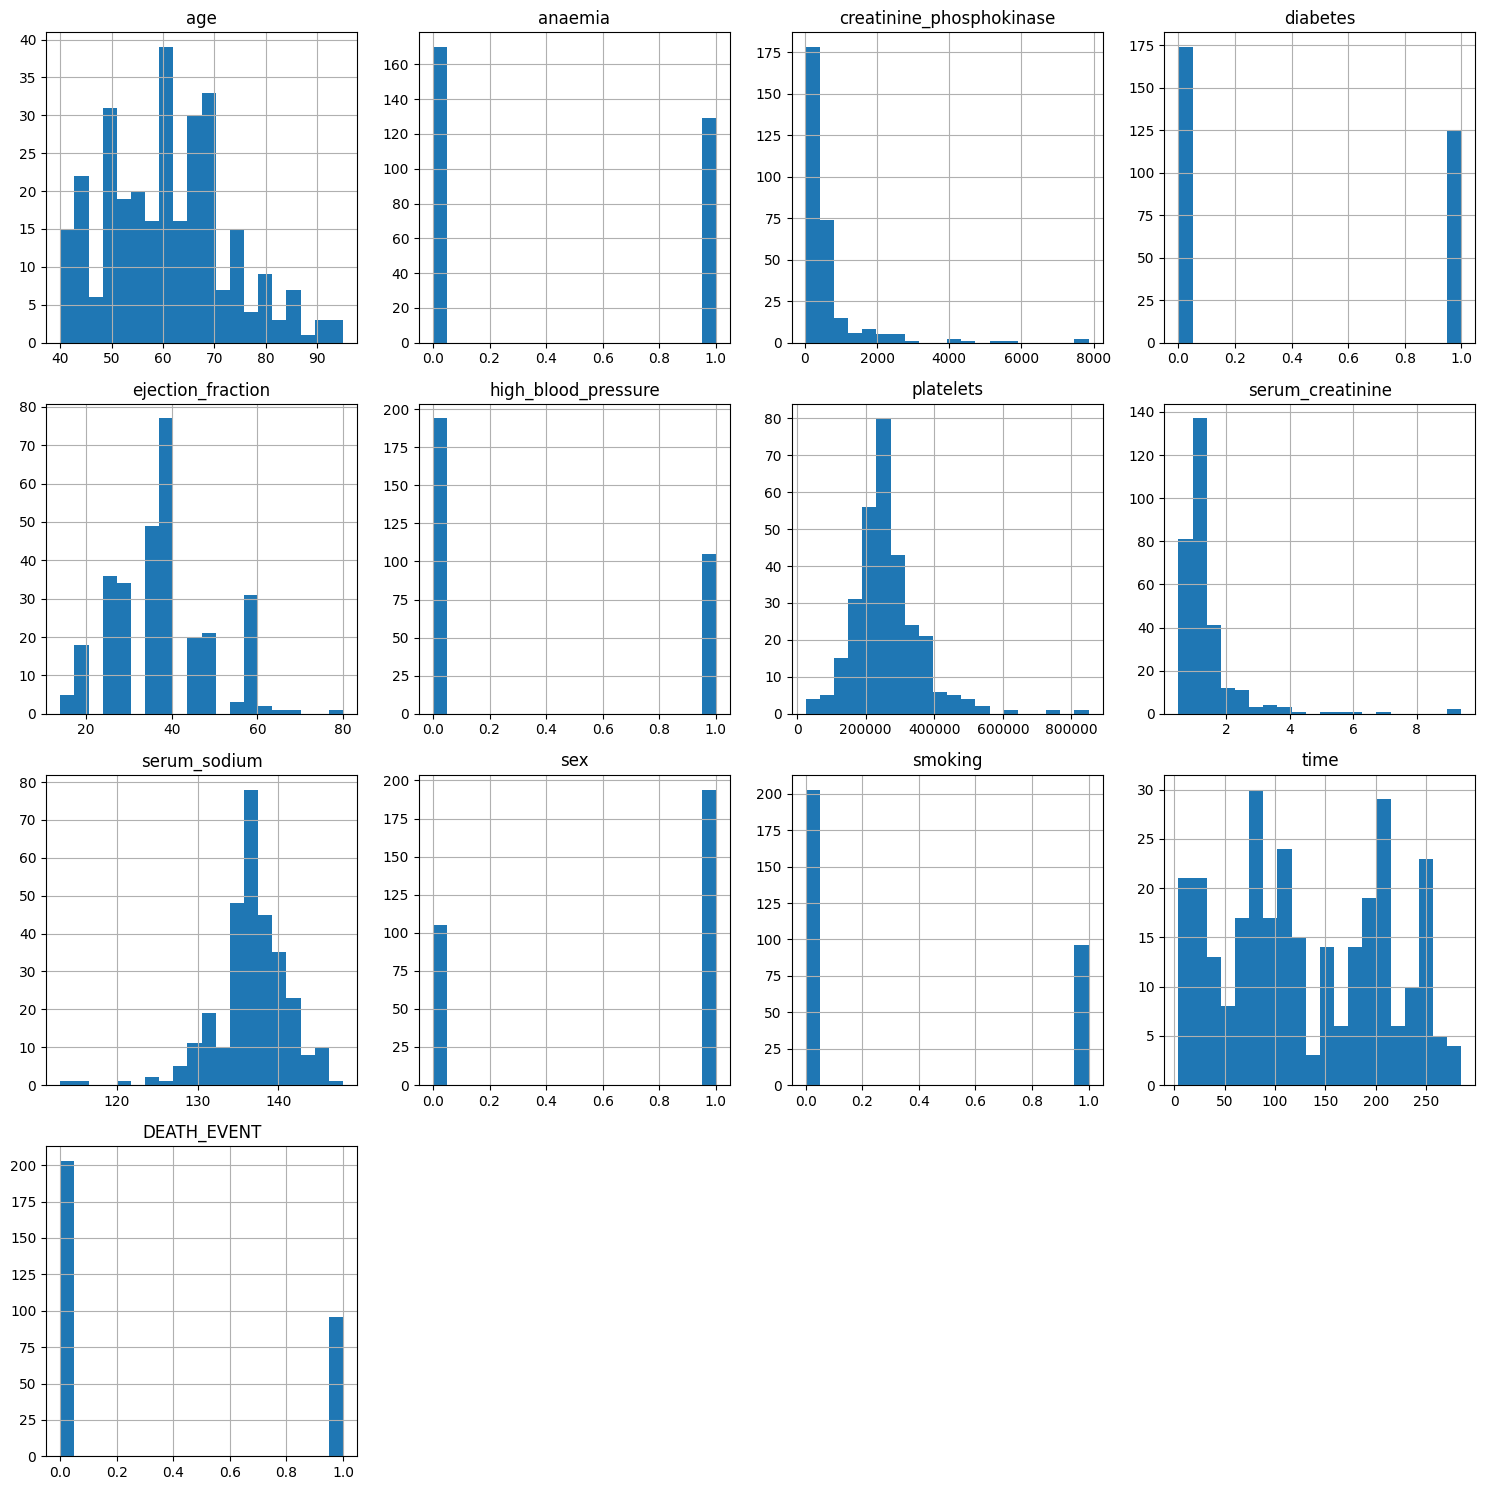

,count
DEATH_EVENT,
0,203
1,96


In [3]:
from numpy import binary_repr
### Question 1

## 1.1: Explore the heart_failure data set and clean it appropriately
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('heart_failure_clinical_records_dataset.csv')
print(df.shape)
print(df.dtypes)
df.info()
df.head()

# Check for missing values = 0
print(df.isnull().sum())

# Check for duplicate rows = 0
print(df.duplicated().sum())

# Check that binary variables are properly coded
print(df['anaemia'].unique())
print(df['diabetes'].unique())
print(df['high_blood_pressure'].unique())
print(df['smoking'].unique())
print(df['sex'].unique())
print(df['DEATH_EVENT'].unique())

# Look at data visualizations
df.hist(figsize = (15, 15), bins=20)
plt.tight_layout()
plt.show()

# Look at response variable
df['DEATH_EVENT'].value_counts()

# The dataset contains 299 observations and 13 numerical variables. There are no missing variables and all
# of the binary variables are correctly coded. No additional data cleaning was needed.


In [4]:
### Question 2

## 2.1: Perform a train-test split for a specific seed (save the seed for reproducibility)
from sklearn.model_selection import train_test_split

y = df['DEATH_EVENT']
X = df.drop(columns=['DEATH_EVENT', 'time'])

seed = 100

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)

## 2.2/2.3: Fit a tree on the training data
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=seed).fit(X_train, y_train)

## 2.4/2.5: Fit a linear model on the training data
from sklearn.linear_model import LinearRegression

linear = LinearRegression().fit(X_train, y_train)
print('Intercept:', linear.intercept_)
pd.Series(linear.coef_, index=X_train.columns)

## 2.6: Evaluate performance on the test data (set aside predictions)
y_pred_tree = tree.predict(X_test)
y_pred_linear = linear.predict(X_test)

print('Tree Accuracy:', tree.score(X_test, y_test))
print('Linear Model R^2:', linear.score(X_test, y_test))

# The decision tree correctly classified 65% of the test observations. The linear model had an R^2 of roughly 0.137 which means
# it explains about 13.7% of the variation in the response variable in the test data.



Intercept: 1.2264567920720628
Tree Accuracy: 0.65
Linear Model R^2: 0.13683194590903713


In [5]:
### Question 3

## 3.1: Repeat step 2 for three to five different seeds (save the seeds for reproducibility).
# most efficient way is thru loop
seeds = [100, 200, 300, 400, 500]
trees = []
linear_models = []
tree_preds = []
linear_preds = []

for s in seeds: # train-test split
    X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
        X, y, test_size=0.2, random_state=s
    )
    # fitting models
    tree_new = DecisionTreeClassifier(random_state=s).fit(X_train_new, y_train_new)
    linear_new = LinearRegression().fit(X_train_new, y_train_new)

    # eval performance
    print('Seed:', s)
    print('Tree Accuracy:', tree_new.score(X_test_new, y_test_new))
    print('Linear Model R^2:', linear_new.score(X_test_new, y_test_new))
    print()

    # save models and preds
    trees.append(tree_new)
    linear_models.append(linear_new)
    tree_preds.append(tree_new.predict(X_test))
    linear_preds.append(linear_new.predict(X_test))


# 3.2: How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
# compare trees
for i in range(len(seeds)):
    print('Seed:', seeds[i])
    print('Depth:', trees[i].get_depth())
    print('Leaves:', trees[i].get_n_leaves())
    print()

# compare linear model coeffs
coeffs = pd.DataFrame(index=X.columns)
for i in range(len(seeds)):
    coeffs[seeds[i]] = linear_models[i].coef_
coeffs.round(4)

# The decision trees varied across the different train-test splits with depths ranging from 11 to 13 and the number of
# leaves ranging from 46 to 53. This suggests that the tree structures are somewhat sensitive to changes in the training
# data. In comparison, many of the linear model coefficients remained pretty consistent, especially for age, ejection fraction,
# and serum creatinine. However, some coefficients like anaemia, diabetes, and smoking varied more with diabetes and smoking
# changing signs across seeds. Overall, the linear models appear more stable in their coefficients, while decision trees
# show greater structural variation.


Seed: 100
Tree Accuracy: 0.65
Linear Model R^2: 0.13683194590903713

Seed: 200
Tree Accuracy: 0.7
Linear Model R^2: 0.00456473919034639

Seed: 300
Tree Accuracy: 0.7166666666666667
Linear Model R^2: 0.23887118988120393

Seed: 400
Tree Accuracy: 0.7666666666666667
Linear Model R^2: 0.2193570335494408

Seed: 500
Tree Accuracy: 0.7166666666666667
Linear Model R^2: -0.02546605503287558

Seed: 100
Depth: 13
Leaves: 52

Seed: 200
Depth: 13
Leaves: 46

Seed: 300
Depth: 12
Leaves: 51

Seed: 400
Depth: 11
Leaves: 51

Seed: 500
Depth: 12
Leaves: 53



,100,200,300,400,500
age,0.0097,0.0104,0.0097,0.0083,0.0092
anaemia,0.0061,0.0652,0.0900,0.0348,0.1107
creatinine_phosphokinase,0.0000,0.0001,0.0000,0.0001,0.0000
diabetes,0.0163,-0.0078,-0.0208,0.0262,0.0449
ejection_fraction,-0.0125,-0.0109,-0.0110,-0.0098,-0.0111
high_blood_pressure,0.0685,0.0439,0.0247,0.0318,0.0605
platelets,-0.0000,-0.0000,0.0000,0.0000,0.0000
serum_creatinine,0.0982,0.0998,0.0845,0.1069,0.1042
serum_sodium,-0.0084,-0.0156,-0.0090,-0.0119,-0.0153
sex,-0.0783,-0.0838,-0.0765,-0.0215,-0.0572


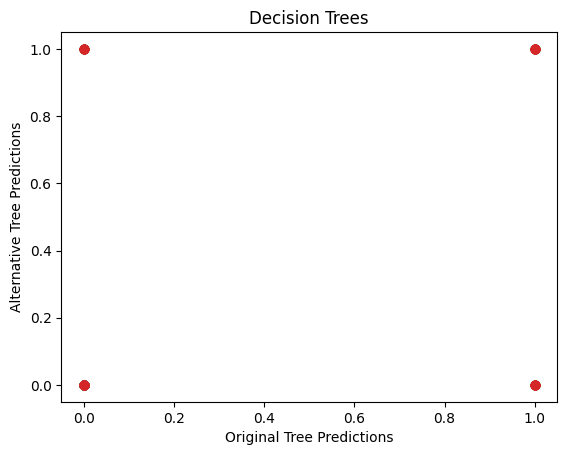

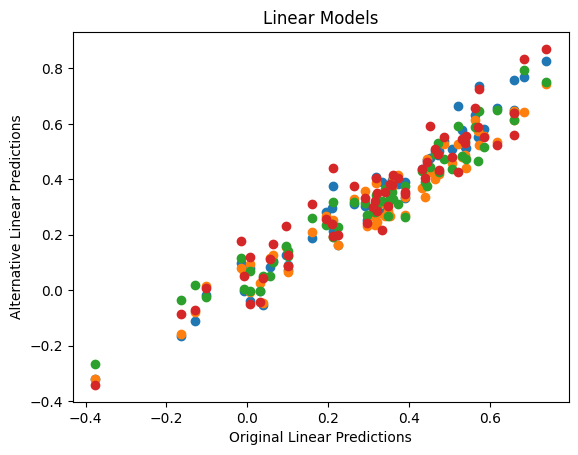

In [6]:
#Question 4.1

#Plotting the predictions from the original decision tree against the predictions from each of the four alternative decision trees on the same test data
for i in range(1, 5):
    plt.scatter(y_pred_tree, tree_preds[i])
plt.xlabel('Original Tree Predictions')
plt.ylabel('Alternative Tree Predictions')
plt.title('Decision Trees')
plt.show()

# Plotting the predictions from the orginial model against the predictions from each of the four alternative linear models on the same test data
for i in range(1, 5):
    plt.scatter(y_pred_linear, linear_preds[i])
plt.xlabel('Original Linear Predictions')
plt.ylabel('Alternative Linear Predictions')
plt.title('Linear Models')
plt.show()

#The linear models look like they make pretty similar predictions across the different train-test splits as we can see with most of the points are clustered closely along a diagonal line. For the decision trees, the points at (0,0) and (1,1) indicate that the original and alternative models agree on whether a patient survived or died, while the points at (0,1) and (1,0) indicate that they make opposite predictions for the same patient. This shows that the trees do not always make the same predictions, but because multiple observations overlap at each point, it's not especially clear how frequently they agree.

In [7]:
#Question 4.2 Calculating the correlation between original and alternative model predictions

# For each alternative decision tree, calculating the correlation between its predictions and the original decision tree's predictions
for i in range(1, 5):
    print('Tree Seed:', seeds[i])
    print('Correlation:', np.corrcoef(y_pred_tree, tree_preds[i])[0, 1])

# same thing for linear models
for i in range(1, 5):
    print('Linear Seed:', seeds[i])
    print('Correlation:', np.corrcoef(y_pred_linear, linear_preds[i])[0, 1])
#The tree correlations range from0.269 from seed 300 t 0.426 from seed 200, indicating a weak positive correlation. This means that the predictions vary pretty often. In contast, the linear models have very high correlations that range from 0.949 to 0.975. the linear models appear to be significanlty more stable in their predictions than the decision trees.

Tree Seed: 200
Correlation: 0.4258373205741626
Tree Seed: 300
Correlation: 0.26901379342448517
Tree Seed: 400
Correlation: 0.28229665071770366
Tree Seed: 500
Correlation: 0.2998772354268913
Linear Seed: 200
Correlation: 0.9745640120091341
Linear Seed: 300
Correlation: 0.9708064525859535
Linear Seed: 400
Correlation: 0.9696461522482734
Linear Seed: 500
Correlation: 0.9493869641884738


In [8]:
#Question 4.3

# Running a linear regression of each alternative decision tree's predictions on the original decision tree's predictions and analyzing the intercept + slope +  R2
for i in range(1, 5):
    reg = LinearRegression().fit(y_pred_tree.reshape(-1, 1), tree_preds[i])
    print('Tree Seed:', seeds[i])
    print('Intercept:', reg.intercept_)
    print('Slope:', reg.coef_[0])
    print('R2:', reg.score(y_pred_tree.reshape(-1, 1), tree_preds[i]))
    print()

# same for the linear mdoels
for i in range(1, 5):
    reg = LinearRegression().fit(y_pred_linear.reshape(-1, 1), linear_preds[i])
    print('Linear Seed:', seeds[i])
    print('Intercept:', reg.intercept_)
    print('Slope:', reg.coef_[0])
    print('R2:', reg.score(y_pred_linear.reshape(-1, 1), linear_preds[i]))
    print()

#The decision trees have intercepts ranging from 0.211 to 0.263 + slopes ranging from 0.263 to 0.426 + relatively low R² values ranging from 0.072 to 0.181. None of these values are particularly close to the desired values of 0 for intercept, 1 for slope, or 1 for R2, suggesting that the decision trees make considerably different predictions across the train-test splits. In comparison, the linear models have intercepts very close to 0, slopes relatively close to 1, and R2 values between 0.901 and 0.950.

Tree Seed: 200
Intercept: 0.21052631578947367
Slope: 0.4258373205741627
R2: 0.18133742359378213

Tree Seed: 300
Intercept: 0.23684210526315785
Slope: 0.2631578947368422
R2: 0.07236842105263175

Tree Seed: 400
Intercept: 0.2631578947368421
Slope: 0.2822966507177034
R2: 0.07969139900643263

Tree Seed: 500
Intercept: 0.2105263157894736
Slope: 0.28947368421052655
R2: 0.08992635632727508

Linear Seed: 200
Intercept: 0.014826777610652486
Slope: 1.0239055004104791
R2: 0.9497750135033398

Linear Seed: 300
Intercept: 0.028365919360694325
Slope: 0.8809600018571547
R2: 0.9424651683825238

Linear Seed: 400
Intercept: 0.04632863939277937
Slope: 0.8790306295671647
R2: 0.9402136605698818

Linear Seed: 500
Intercept: 0.05050313837620679
Slope: 0.9333703550512904
R2: 0.9013356077710071



Question 5: The linear models appear to have relatively similar coefficients across the different train-test splits. We can see this in variables like age. Linear model predictions have high correlations ranging from 0.949 to 0.975 and R2 values ranging from 0.901 to 0.950. This lies in contrast to the decision tree models. The depths of the trees vary from 11 to 13 and leaves range from 46 to 53 and the correlations range from 0.269 to 0.426 and it has much lower R2 values.

Question 6: False, decision trees are the evidence here. Even though the decision trees only vary somewhat in their depth and number of leaves, their predictions have relatively low correlations ranging from 0.269 to 0.426 and low R2 values. This suggests that changes in the structure of decision trees can lead to substantial differences in their predictions, whereas the linear models remain much more consistent.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]